# Tracer-noise scheme: lagged or current amplitude

Runs from `scheme_run.py` (files in `output/`). The two schemes differ only in the tracer noise amplitude $\sigma_\theta$:

- **lagged**: tracers → noise → momentum, $\sigma_\theta$ from the diffusivity of the previous step (current experiment loop)
- **current**: noise → tracers → momentum, $\sigma_\theta$ from the diffusivity of the current step

**Decision rule**
1. A scheme that blows up at $\Delta t = 1800$ s (the time step of the experiments) is rejected.
2. The retained scheme must converge in $\Delta t$: its MLD at 1800 s close (a few m) to its MLD at 300 s.
3. If both schemes are stable at 300 s, they must agree there (same continuous limit).

In [1]:
import os, json
import numpy as np
import matplotlib.pyplot as plt

OUT    = 'output'
WINDOW = (10.0, 40.0)            # days used in the summary

with open(os.path.join(OUT, 'runs.json')) as f:
    info = json.load(f)
CLOSURES, DTS, RUNS = info['closures'], info['dts'], info['runs']
REC_HOURS = info['rec_hours']

def load(closure, name):
    path = os.path.join(OUT, f'{closure}_{name}.npz')
    return dict(np.load(path)) if os.path.exists(path) else None

DATA = {(c, n): load(c, n) for c in CLOSURES for n in RUNS}
print('missing runs:', [k for k, d in DATA.items() if d is None])

missing runs: []


## Summary over the window

In [2]:
def window_mean(d, key):
    sel = (d['t'] >= WINDOW[0]) & (d['t'] <= WINDOW[1])
    return np.nanmean(d[key][sel])

def mld_distance(d1, d2):
    '''Mean |MLD1 - MLD2| over the window, on a common 3-h grid (m).'''
    t = np.arange(WINDOW[0], WINDOW[1], REC_HOURS / 24)
    return np.nanmean(np.abs(np.interp(t, d1['t'], d1['mld_m']) - np.interp(t, d2['t'], d2['mld_m'])))

for c in CLOSURES:
    print(f'\n=== {c} ===')
    print(f'{"run":>16s} | {"max blow":>8s} | {"MLD (m)":>14s} | {"SST (C)":>7s}')
    for name in RUNS:
        d = DATA[(c, name)]
        if d is None:
            continue
        print(f'{name:>16s} | {np.nanmax(d["blow"]):8.2f} | '
              f'{window_mean(d, "mld_m"):6.1f} +- {window_mean(d, "mld_s"):4.1f} | '
              f'{window_mean(d, "sst"):7.2f}')


=== k-kl ===
             run | max blow |        MLD (m) | SST (C)
   lagged_dt1800 |     0.00 |   30.9 +- 15.6 |   22.66
    lagged_dt600 |     0.00 |   34.8 +- 15.7 |   22.51
    lagged_dt300 |     0.00 |   36.2 +- 15.9 |   22.51
  current_dt1800 |     1.00 |   27.3 +- 24.9 |   22.39
   current_dt600 |     0.97 |   29.8 +- 15.2 |   22.69
   current_dt300 |     0.54 |   32.9 +- 16.6 |   22.55
      noT_dt1800 |     0.00 |   19.3 +-  3.0 |   22.76

=== k-epsilon ===
             run | max blow |        MLD (m) | SST (C)
   lagged_dt1800 |     0.00 |   28.0 +- 14.9 |   22.71
    lagged_dt600 |     0.00 |   33.0 +- 15.2 |   22.57
    lagged_dt300 |     0.00 |   34.9 +- 15.6 |   22.51
  current_dt1800 |     1.00 |    nan +-  nan |     nan
   current_dt600 |     1.00 |   26.2 +- 16.7 |   22.57
   current_dt300 |     1.00 |   29.0 +- 17.5 |   23.27
      noT_dt1800 |     0.00 |   19.0 +-  2.9 |   22.74

=== tke ===
             run | max blow |        MLD (m) | SST (C)
   lagged_dt1800 | 

/tmp/ipykernel_31837/2870630116.py:3: RuntimeWarning: Mean of empty slice
  return np.nanmean(d[key][sel])


## Criteria 2 and 3: convergence in $\Delta t$ and agreement between schemes

In [3]:
ref = DTS[-1]
for c in CLOSURES:
    print(f'\n=== {c} ===')
    for s in ('lagged', 'current'):
        d_ref = DATA[(c, f'{s}_dt{ref}')]
        parts = [f'{mld_distance(DATA[(c, f"{s}_dt{dt}")], d_ref):.1f} m ({dt} s)'
                 for dt in DTS[:-1] if d_ref is not None and DATA[(c, f'{s}_dt{dt}')] is not None]
        print(f'  {s:>8s}: |MLD(dt) - MLD({ref} s)| = ' + ', '.join(parts))
    for dt in DTS:
        a, b = DATA[(c, f'lagged_dt{dt}')], DATA[(c, f'current_dt{dt}')]
        if a is not None and b is not None:
            print(f'  dt = {dt:4d} s: |MLD lagged - MLD current| = {mld_distance(a, b):5.1f} m, '
                  f'max blow lagged = {np.nanmax(a["blow"]):.2f}, current = {np.nanmax(b["blow"]):.2f}')


=== k-kl ===
    lagged: |MLD(dt) - MLD(300 s)| = 5.4 m (1800 s), 2.4 m (600 s)
   current: |MLD(dt) - MLD(300 s)| = 9.6 m (1800 s), 4.2 m (600 s)
  dt = 1800 s: |MLD lagged - MLD current| =   9.1 m, max blow lagged = 0.00, current = 1.00
  dt =  600 s: |MLD lagged - MLD current| =   5.2 m, max blow lagged = 0.00, current = 0.97
  dt =  300 s: |MLD lagged - MLD current| =   3.3 m, max blow lagged = 0.00, current = 0.54

=== k-epsilon ===
    lagged: |MLD(dt) - MLD(300 s)| = 6.9 m (1800 s), 2.5 m (600 s)
   current: |MLD(dt) - MLD(300 s)| = nan m (1800 s), 13.5 m (600 s)
  dt = 1800 s: |MLD lagged - MLD current| =   nan m, max blow lagged = 0.00, current = 1.00
  dt =  600 s: |MLD lagged - MLD current| =  12.9 m, max blow lagged = 0.00, current = 1.00
  dt =  300 s: |MLD lagged - MLD current| =   7.4 m, max blow lagged = 0.00, current = 1.00

=== tke ===
    lagged: |MLD(dt) - MLD(300 s)| = 5.5 m (1800 s), 2.7 m (600 s)
   current: |MLD(dt) - MLD(300 s)| = 4.4 m (1800 s), 2.1 m (600 s)

/tmp/ipykernel_31837/2870630116.py:8: RuntimeWarning: Mean of empty slice
  return np.nanmean(np.abs(np.interp(t, d1['t'], d1['mld_m']) - np.interp(t, d2['t'], d2['mld_m'])))


## Figure

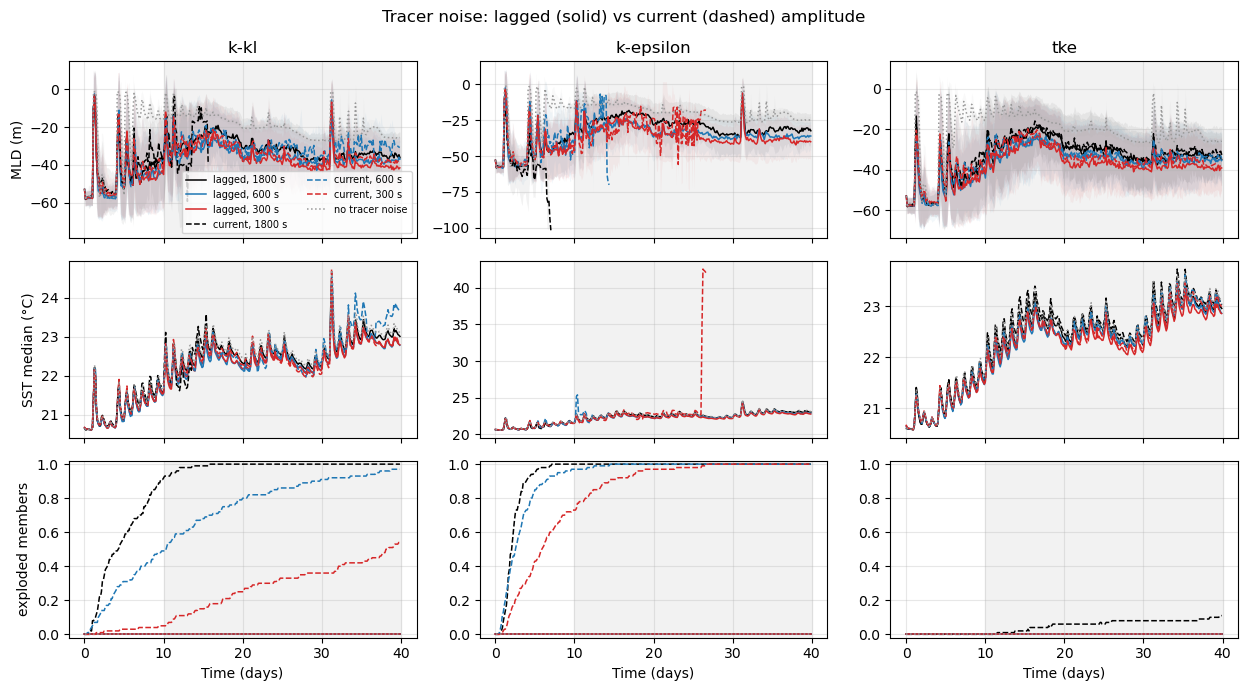

In [4]:
colours = {1800: 'k', 600: 'C0', 300: 'C3'}
rows = [('mld_m', 'MLD (m)'), ('sst', 'SST median (°C)'), ('blow', 'exploded members')]

fig, ax = plt.subplots(len(rows), len(CLOSURES), figsize=(4.2 * len(CLOSURES), 7),
                       sharex=True, squeeze=False)
for j, c in enumerate(CLOSURES):
    for name, r in RUNS.items():
        d = DATA[(c, name)]
        if d is None:
            continue
        if not r['temp_noise']:
            col, ls, label = '0.6', ':', 'no tracer noise'
        else:
            col, ls = colours[r['dt']], ('-' if r['scheme'] == 'lagged' else '--')
            label = f"{r['scheme']}, {r['dt']} s"
        for i, (key, _) in enumerate(rows):
            y = -d[key] if key == 'mld_m' else d[key]
            ax[i, j].plot(d['t'], y, color=col, ls=ls, lw=1.1, label=label if i == 0 else None)
            if key == 'mld_m':
                ax[i, j].fill_between(d['t'], y - d['mld_s'], y + d['mld_s'], color=col, alpha=0.05, lw=0)
    ax[0, j].set_title(c)
    ax[2, j].set_ylim(-0.02, 1.02)
    ax[-1, j].set_xlabel('Time (days)')
for i, (_, ylabel) in enumerate(rows):
    ax[i, 0].set_ylabel(ylabel)
for a in ax.flat:
    a.grid(alpha=0.3)
    a.axvspan(*WINDOW, color='0.95', zorder=0)
ax[0, 0].legend(fontsize=7, ncol=2)
fig.suptitle('Tracer noise: lagged (solid) vs current (dashed) amplitude')
fig.tight_layout()